# Week 6 with new API interface

In [1]:
import jax
jax.config.update("jax_enable_x64", True) 

In [2]:
from src.api.v5 import (
    GaussEmission, 
    StaticTransition, 
    DynamicTransition,
    Params, 
    LBFGSSolver, 
    AutoregressiveGaussEmission, 
    MultivariateAutoregressiveGaussEmission, 
    MultivariateGaussEmission
    )


from drivers.utils import (
    load_y_df, 
    build_covariates, 
    harmonic_range, 
    load_base_data_path
    )
import numpy as np
import jax.numpy as jnp
from dataclasses import dataclass
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
  

In [3]:
ROOM_SLUG, TAG  = "room_001", "30min"  
STATES = 4 

# --- Covariates entering the transition -------------------------------------------
USE_OFF_DAY     = True     # weekend / Danish public holiday flag


# --- Calendar cycles (0 drops the block entirely) ---------------------------------
N_DAILY_CYCLES  = [1]     # -> sin_tod_1..k  / cos_tod_1..k
N_WEEKLY_CYCLES = [1]     # -> sin_week_1..k / cos_week_1..k


In [4]:

data_dir = Path(load_base_data_path()) / ROOM_SLUG / TAG
meta     = pd.read_csv(data_dir / "metadata.csv").iloc[0]
BIN          = meta["bin"]


ys_train_df = load_y_df(ROOM_SLUG, TAG, "train")  # the driver's X_*.csv are not used: 

dates     = pd.date_range(meta["start"], periods=len(ys_train_df), freq=BIN)

X_raw, covariate_cols = build_covariates(
    dates,
    tod_harmonics=harmonic_range(N_DAILY_CYCLES),
    week_harmonics=harmonic_range(N_WEEKLY_CYCLES),
    use_off_day=USE_OFF_DAY,
    weather_cols=[],
)

ys_train_df = ys_train_df.set_index("datetime").sort_index()  # sort by datetime, just in case 

print(f"Loaded {ROOM_SLUG}/{TAG} — {ys_train_df.shape[0]} training observations") 
print(f"Covarite cols is: {covariate_cols}")
print(f"First 5 rows of training data:\n{ys_train_df.head()}")

Loaded room_001/30min — 2752 training observations
Covarite cols is: ['off_day', 'sin_week_1', 'cos_week_1', 'sin_tod_1', 'cos_tod_1']
First 5 rows of training data:
                            co2  humidity
datetime                                 
2023-11-13 04:00:00  502.786667  2.945788
2023-11-13 04:30:00  472.413333  2.945788
2023-11-13 05:00:00  493.706667  2.743398
2023-11-13 05:30:00  498.000000  2.743398
2023-11-13 06:00:00  481.293333  2.919637


In [5]:
@dataclass(frozen=True)
class Data:
    ys: jnp.ndarray
    datetime: pd.Series
    ys_co2: jnp.ndarray
    ys_humidity: jnp.ndarray
    xs: jnp.ndarray  # covariates for transition
    ys_cols: tuple[str] = ("co2", "humidity") # type: ignore



traindata = Data(
    ys=jnp.array(ys_train_df.values),
    datetime=ys_train_df.index,
    ys_co2=jnp.array(ys_train_df["co2"].values),
    ys_humidity=jnp.array(ys_train_df["humidity"].values),
    xs=jnp.asarray(X_raw),
    ys_cols=tuple(ys_train_df.columns)
)



results_dict = {}

## Data plots of CO2 and Humidity

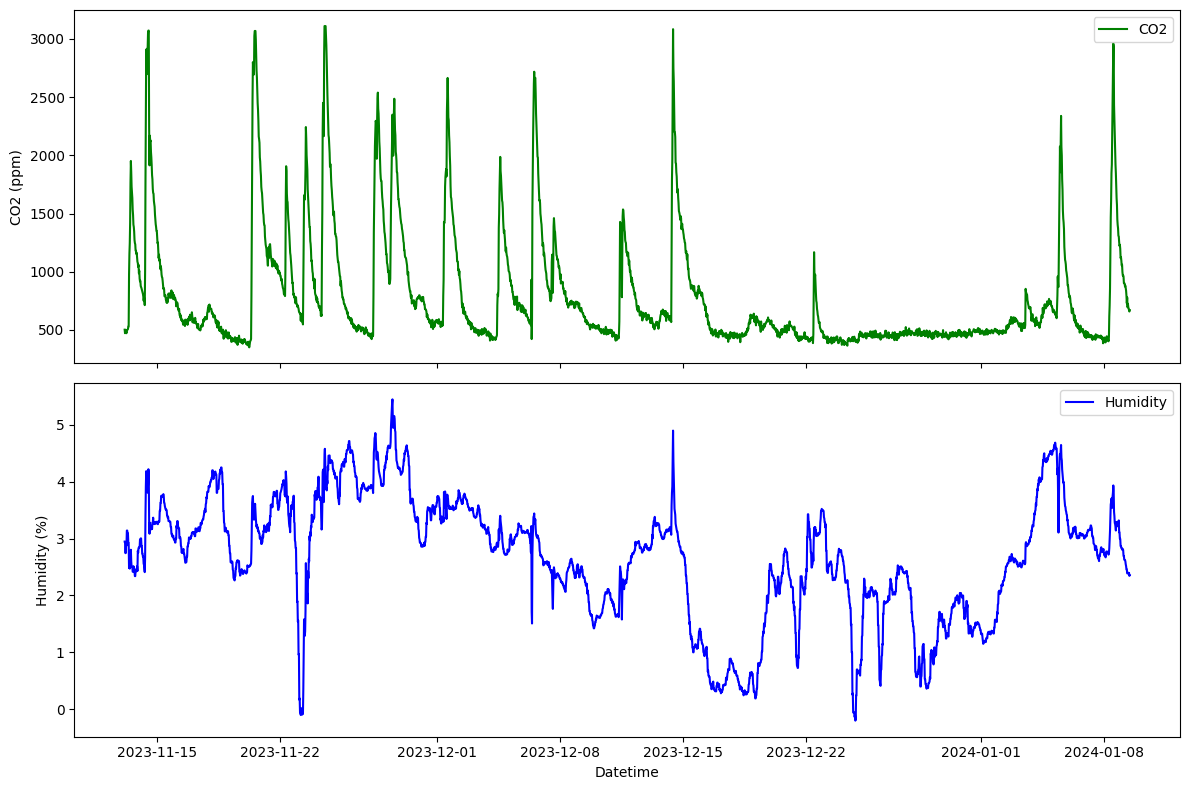

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axs[0].plot(traindata.datetime, traindata.ys_co2, label="CO2", color="green")
axs[0].set_ylabel("CO2 (ppm)")
axs[0].legend()
axs[1].plot(traindata.datetime, traindata.ys_humidity, label="Humidity", color="blue")
axs[1].set_ylabel("Humidity (%)")
axs[1].set_xlabel("Datetime")
axs[1].legend()
plt.tight_layout()

In [7]:
correl = ys_train_df.corr()

print(f"Correlation between CO2 and Humidity:\n{correl}")

Correlation between CO2 and Humidity:
               co2  humidity
co2       1.000000  0.424673
humidity  0.424673  1.000000


Correlation between standardized CO2 and Humidity: 0.4247


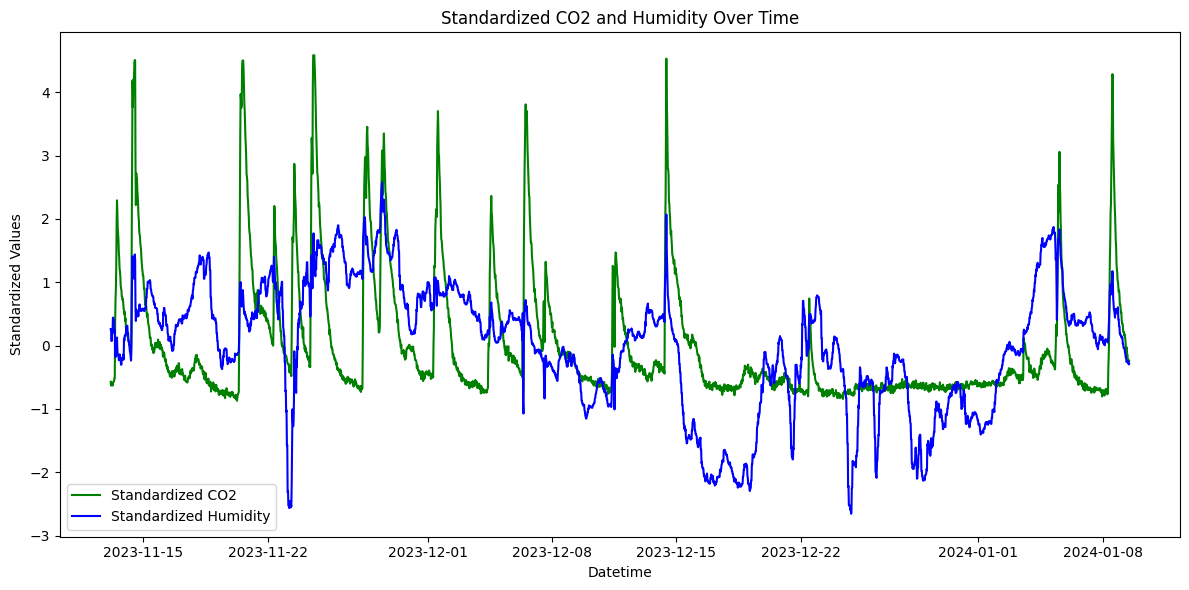

In [8]:
def standardise(x: jnp.ndarray) -> tuple:
    """Standardise a 1D array to have mean 0 and std 1."""
    mean = jnp.mean(x)
    std = jnp.std(x)
    z = (x - mean) / std
    return z, mean, std 


stand_co2, mean_co2, std_co2 = standardise(traindata.ys_co2)
stand_humidity, mean_hum, std_hum = standardise(traindata.ys_humidity)

correl_stand = jnp.corrcoef(stand_co2, stand_humidity)[0, 1] 


#Plot standardized CO2 and Humidity together
plt.figure(figsize=(12, 6))
plt.plot(traindata.datetime, stand_co2, label="Standardized CO2", color="green")
plt.plot(traindata.datetime, stand_humidity, label="Standardized Humidity", color="blue")
plt.ylabel("Standardized Values")
plt.xlabel("Datetime")
plt.title("Standardized CO2 and Humidity Over Time")
plt.legend()
plt.tight_layout()



print(f"Correlation between standardized CO2 and Humidity: {correl_stand:.4f}")

# Fitting 

In [9]:
def negative_likelihood(params: Params, data: tuple) -> jax.Array:
    """Compute the negative log-likelihood of the HMM given the parameters and data."""
    from src.api.v5 import ForwardAlgorithm 
    ys, xs, inital_dist = data
    utt, f_t, u_t = ForwardAlgorithm().run(params=params, ys=ys, xs=xs, initial_dist=inital_dist)  
    val = -jnp.sum(jnp.log(f_t))  # negative log-likelihood
    return val 
    


def compute_stationary_distribution(transition_matrix: jnp.ndarray) -> jnp.ndarray:
    """Compute the stationary distribution of a Markov chain given its transition matrix."""
    num_states = transition_matrix.shape[0]
    I = jnp.eye(num_states)
    E = jnp.ones((num_states, num_states))
    e = jnp.ones((num_states, 1))
    delta = e.T @ jnp.linalg.inv(I - transition_matrix + E)
    return delta / jnp.sum(delta)  # Normalize to sum to 1



import equinox as eqx
import optax.tree_utils as otu

def nll_fixed_mu0(params: Params, data: tuple) -> jax.Array:
    """NLL with mu0 forced to the value carried in data, so it can't be optimised."""
    mu0, inner = data
    return negative_likelihood(eqx.tree_at(lambda p: p.emission.mu0, params, mu0), inner)


def profile_likelihood_mu0(mu0_range: jnp.ndarray, params: Params, data: tuple, solver: LBFGSSolver) -> jnp.ndarray:
    """Profile the negative log-likelihood over a range of mu0 values (vmapped)."""
    def fit_one(mu0):
        _, state = solver._run(nll_fixed_mu0, params, (mu0, data))
        return otu.tree_get(state, "value")
    return jax.vmap(fit_one)(mu0_range)


from jax.flatten_util import ravel_pytree
from jax.scipy.linalg import cho_factor, cho_solve


def compute_hessian(fitted_params: Params, data: tuple) -> tuple:
    """Compute the Hessian of the negative log-likelihood at the fitted parameters."""
    fit = fitted_params                                   # your MLE
    arrays, static = eqx.partition(fit, eqx.is_array)       # trainable leaves vs the rest
    theta_hat, unravel = ravel_pytree(arrays)               # flat vector + inverse map
    def nll_flat(theta):
        return negative_likelihood(eqx.combine(unravel(theta), static), data)
    H = jax.hessian(nll_flat)(theta_hat) # (p, p) observed information
    return H, unravel

def scale_hessian(H: jax.Array) -> tuple: 
    d = jnp.sqrt(jnp.diag(H))
    Hs = H / jnp.outer(d, d)  
    return Hs, d 


def compute_working_standard_errors(fitted_params: Params, data: tuple) -> Params:
    """Compute standard errors from the Hessian."""
    H, unravel = compute_hessian(fitted_params=fitted_params, data=data)            # exact Hessian via autodiff
    Hs, d = scale_hessian(H)                     # unit diagonal, same information
    cov = cho_solve(cho_factor(Hs), jnp.eye(len(d))) / jnp.outer(d, d)
    se = jnp.sqrt(jnp.diag(cov))
    params_std_errors = unravel(se)
    return params_std_errors



def get_gradient(params: Params, data: tuple) -> jax.Array:
    """Compute the gradient of the negative log-likelihood at the given parameters.""" 
    fit = params                                   # your MLE
    arrays, static = eqx.partition(fit, eqx.is_array)       # trainable leaves vs the rest
    theta_hat, unravel = ravel_pytree(arrays)               # flat vector + inverse map
    def nll_flat(theta):
        return negative_likelihood(eqx.combine(unravel(theta), static), data)
    return jax.grad(nll_flat)(theta_hat) 


def hessian_labels(params: Params) -> list[str]:
    """One label per entry of the flat vector from ravel_pytree, in the same order."""
    arrays, _ = eqx.partition(params, eqx.is_array)
    leaves_with_path, _ = jax.tree_util.tree_flatten_with_path(arrays)   # same leaf order as ravel_pytree
    labels = []
    for path, leaf in leaves_with_path:
        name = jax.tree_util.keystr(path).lstrip(".")                    # e.g. "emission.log_sigma"
        if name.endswith("transition_logits"):
            # logits[i, k] is the off-diagonal entry Γ[i, j] with j = k (k < i) or k + 1 (k >= i)
            m = leaf.shape[0]
            for i, k in np.ndindex(leaf.shape):
                j = k if k < i else k + 1
                labels.append(f"{name}[{i}->{j}]")
        elif leaf.ndim == 0:
            labels.append(name)
        else:
            labels.extend(f"{name}[{','.join(map(str, idx))}]" for idx in np.ndindex(leaf.shape))
    return labels



In [10]:
#Seeding data

mu_seed = jnp.quantile(traindata.ys_co2, jnp.linspace(0.05, 0.95, STATES), axis=0)  # initial guess for means
std_seed = jnp.std(traindata.ys_co2, axis=0) * jnp.ones((STATES, ))  # initial guess for stds 
emission = GaussEmission.from_params(mu=mu_seed, sigma=std_seed)  # emission distribution


transition_matrix = jnp.diag(jnp.ones(STATES)) * 0.7 + jnp.ones((STATES, STATES)) * 0.3 / STATES  # initial guess for transition matrix
transition = StaticTransition.from_params(transition_matrix=transition_matrix)  # transition distribution


#inital_dist = compute_stationary_distribution(transition_matrix)  # initial distribution: stationary distribution of the transition matrix
inital_dist = jnp.ones((1 ,STATES)) / STATES  # initial distribution: uniform distribution over states

data = (traindata.ys_co2, None, inital_dist)  # initial distribution: all in state 0

## Fitting Univariate Model

### HMM(1)

In [11]:


emission = GaussEmission.from_params(mu=mu_seed, sigma=std_seed)  # emission distribution
transition = StaticTransition.from_params(transition_matrix=transition_matrix)  # transition distribution
gauss_params = Params(emission=emission, transition=transition)  # combine into Params object



solver = LBFGSSolver(n_iter=10_000)  # number of iterations for the optimizer

results = solver.fit(params=gauss_params, loss_fn=negative_likelihood, data=data)  # solve for parameters
fitted_gauss_params = results.params  # fitted parameters

print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Estimated mu0: {results.params.emission.mu0}")

results_dict["HMM(1)"] = results

Final loss: 16450.4731085659
Converged: True
Estimated mu0: 419.6461589290379


In [12]:
#We see that the conditioin number is very high
H, unravel = compute_hessian(fitted_params=fitted_gauss_params, data=data)

print(f"Condtion number of HMM(1) is: {jnp.linalg.cond(H)}")
#We compute min eigenvalue we trust

w = jnp.linalg.eigh(H)[0]
eps = jnp.finfo(H.dtype).eps          # eps of the dtype you actually computed in

print(f"Machine precision is: {eps}")

tol = H.shape[0] * eps * jnp.max(jnp.abs(w))

print(f"Tolerance is: {tol}")

numerically_zero = jnp.abs(w) <= tol

print(f"Number of numerical Zeros eigenvals: {jnp.sum(numerically_zero)}")
truly_negative   = w < -tol


print("----------------------")
Hs, d  = scale_hessian(H=H)
print(f"Condition number of scaled Hessian: {jnp.linalg.cond(Hs)}")
ws = jnp.linalg.eigh(Hs)[0]
tols = Hs.shape[0] * eps * jnp.max(jnp.abs(ws))
print(f"Tolerance is: {tols}")
numerically_zero = jnp.abs(ws) <= tols
print(f"Number of numerical Zeros eigenvals: {jnp.sum(numerically_zero)}")

Condtion number of HMM(1) is: 5791012845644.868
Machine precision is: 2.220446049250313e-16
Tolerance is: 1.4468017102728906e-11
Number of numerical Zeros eigenvals: 0
----------------------
Condition number of scaled Hessian: 9.991411236681842
Tolerance is: 9.257535833877857e-15
Number of numerical Zeros eigenvals: 0


In [13]:
mu_0=fitted_gauss_params.emission.mu0 
params_std_errors = compute_working_standard_errors(fitted_params=fitted_gauss_params, data=data) 

std = params_std_errors.emission.mu0 

print(f"Estimated mu0: {mu_0:.4f}, SE: {std:.4f}")

mu0_range = jnp.linspace(mu_0 - 3*std, mu_0 + 3*std, 60)  # range of mu0 values to profile

nll = profile_likelihood_mu0(mu0_range, results.params, data, LBFGSSolver(n_iter=1000))

Estimated mu0: 419.6462, SE: 1.4444


Text(0, 0.5, 'Likelihood')

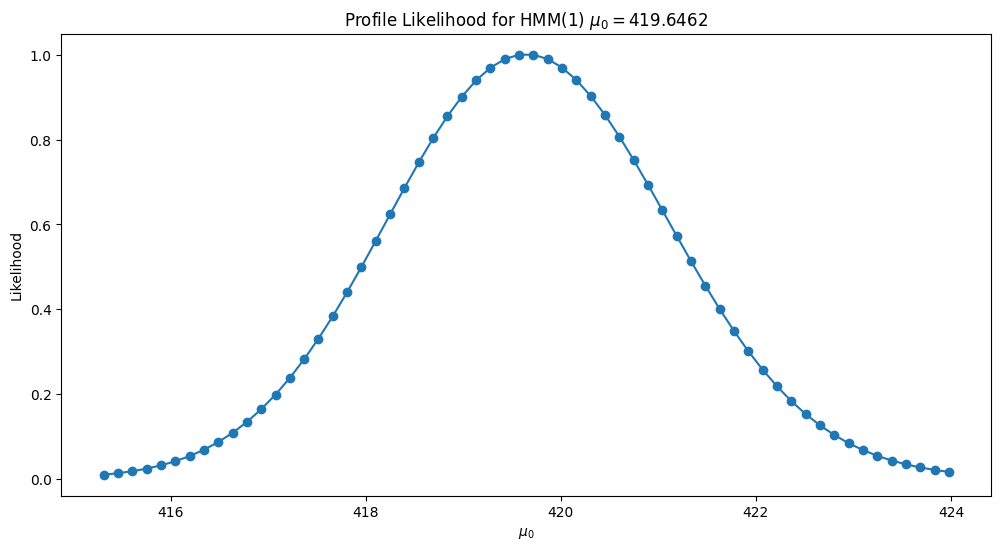

In [14]:
#Plot profile likelihood
ll = -nll  # Convert negative log-likelihood to log-likelihood for plotting
profile_likelihoods = jnp.exp(ll - jnp.max(ll))  # Convert negative log-likelihood to likelihood for plotting
plt.figure(figsize=(12, 6))
plt.plot(mu0_range, profile_likelihoods, marker='o')
plt.title(f"Profile Likelihood for HMM(1) $\mu_0=${mu_0:.4f}")
plt.xlabel("$\mu_0$")
plt.ylabel("Likelihood")

### HMM( $\beta$, 1)

In [15]:
emission = results_dict["HMM(1)"].params.emission 
transition_matrix = results_dict["HMM(1)"].params.transition.transition_matrix()
beta_init = jnp.ones((len(covariate_cols), transition_matrix.shape[0], transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransition.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 
  # transition distribution

In [16]:
data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters
print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")

results_dict["HMM(b,1)"] = results 

Final loss: 16369.116842974487
Converged: False


In [17]:
#We see that the conditioin number is very high
H, unravel = compute_hessian(fitted_params=results.params, data=data)

Hs, d = scale_hessian(H)
ws = jnp.linalg.eigh(Hs)[0]
tols = Hs.shape[0] * eps * jnp.max(jnp.abs(ws))
print(f"Tolerance is: {tols}")
numerically_zero = jnp.abs(ws) <= tols
print(f"Number of numerical Zeros eigenvals: {jnp.sum(numerically_zero)}")
#print(ws)

Tolerance is: 8.764720944495566e-14
Number of numerical Zeros eigenvals: 0


In [18]:
gradient = get_gradient(params=results.params, data=data)
print(f"Gradient norm: {jnp.linalg.norm(gradient)}")

Gradient norm: 0.07020304822419791


In [19]:
g = get_gradient(params=results.params, data=data)
H, unravel = compute_hessian(fitted_params=results.params, data=data)
labels = hessian_labels(results.params)
step = jnp.linalg.solve(H, g)              # Newton step to the (local) optimum
se = jnp.sqrt(jnp.diag(jnp.linalg.inv(H)))
print("Newton decrement (expected NLL drop):", 0.5 * g @ step)
df = pd.DataFrame({"grad": g, "step": step, "step/se": step / se}, index=labels)
print(df.reindex(df["step/se"].abs().sort_values(ascending=False).index).head(15))

Newton decrement (expected NLL drop): 0.3084876487942254
                                        grad        step   step/se
transition.transition_logits[0->1]  0.003248   95.783807  0.733438
transition.beta[3,0,0]             -0.003593 -100.600854 -0.694319
transition.beta[1,0,0]              0.002052 -157.241149 -0.685689
transition.beta[0,0,0]              0.002828 -152.711652 -0.685463
transition.beta[2,0,0]              0.006516   77.559410  0.679320
transition.beta[4,0,1]              0.003058  -18.929833 -0.490966
transition.beta[1,0,1]             -0.004714 -141.285631 -0.481487
transition.beta[3,0,1]             -0.012207   -5.703298 -0.362579
transition.beta[0,0,1]              0.000054   47.702679  0.285651
transition.transition_logits[0->2] -0.013508   59.016751  0.284843
transition.beta[2,0,1]             -0.012723  -22.874421 -0.138978
transition.beta[4,0,0]              0.002459    1.552791  0.117937
transition.beta[4,1,1]             -0.011033   -0.177810 -0.057095
trans

In [20]:
#Printing wald conf intervals for the beta parameters
errors = compute_working_standard_errors(fitted_params=results.params, data=data) 

beta_vals = [results.params.transition.beta[i, j,k] for i in range(results.params.transition.beta.shape[0]) for j in range(results.params.transition.beta.shape[1]) for k in range(results.params.transition.beta.shape[2])]

errors_beta =[errors.transition.beta[i, j, k] for i in range(results.params.transition.beta.shape[0]) for j in range(results.params.transition.beta.shape[1]) for k in range(results.params.transition.beta.shape[2] )]

names = [f"beta[{i},{j},{k}]" for i in covariate_cols for j in range(results.params.transition.beta.shape[1]) for k in range(results.params.transition.beta.shape[2] + 1) if j!=k] 

for name, val, err in zip(names, beta_vals, errors_beta):
    ci_lower = val - 1.96 * err
    ci_upper = val + 1.96 * err
    print(f"{name}: Estimate={val:.4f}, SE={err:.4f}, 95% CI=({ci_lower:.4f}, {ci_upper:.4f})")

beta[off_day,0,1]: Estimate=132.5178, SE=nan, 95% CI=(nan, nan)
beta[off_day,0,2]: Estimate=-29.5300, SE=nan, 95% CI=(nan, nan)
beta[off_day,0,3]: Estimate=-91.9014, SE=nan, 95% CI=(nan, nan)
beta[off_day,1,0]: Estimate=4.0831, SE=nan, 95% CI=(nan, nan)
beta[off_day,1,2]: Estimate=-19.3541, SE=nan, 95% CI=(nan, nan)
beta[off_day,1,3]: Estimate=-16.1942, SE=nan, 95% CI=(nan, nan)
beta[off_day,2,0]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[off_day,2,1]: Estimate=-0.7236, SE=nan, 95% CI=(nan, nan)
beta[off_day,2,3]: Estimate=-24.0594, SE=nan, 95% CI=(nan, nan)
beta[off_day,3,0]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[off_day,3,1]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[off_day,3,2]: Estimate=0.0771, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,0,1]: Estimate=133.1452, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,0,2]: Estimate=63.7726, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,0,3]: Estimate=-57.3866, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,1,0]: Estimate=1.8865, SE=n

In [21]:
H, unravel = compute_hessian(results.params, data)
labels = hessian_labels(results.params)
diag = np.asarray(jnp.diag(H))
print("NaN in H:", bool(jnp.any(jnp.isnan(H))))
print("min eig H:", jnp.linalg.eigvalsh(H)[:5])
print("near-zero curvature:", [l for l, h in zip(labels, diag) if h < 1e-6])

NaN in H: False
min eig H: [-4.27051287e-04  1.80307169e-11  1.81459866e-11  5.29161870e-11
  1.34222356e-10]
near-zero curvature: ['transition.transition_logits[2->0]', 'transition.transition_logits[3->0]', 'transition.transition_logits[3->1]', 'transition.beta[0,0,2]', 'transition.beta[0,1,1]', 'transition.beta[0,1,2]', 'transition.beta[0,2,0]', 'transition.beta[0,2,2]', 'transition.beta[0,3,0]', 'transition.beta[0,3,1]', 'transition.beta[1,2,0]', 'transition.beta[1,3,0]', 'transition.beta[1,3,1]', 'transition.beta[2,2,0]', 'transition.beta[2,3,0]', 'transition.beta[2,3,1]', 'transition.beta[3,2,0]', 'transition.beta[3,3,0]', 'transition.beta[3,3,1]', 'transition.beta[4,2,0]', 'transition.beta[4,3,0]', 'transition.beta[4,3,1]']


In [22]:
w, V = jnp.linalg.eigh(H)
v = pd.Series(np.asarray(V[:, 0]), index=labels)          # eigenvector of the negative eigenvalue
print(v.reindex(v.abs().sort_values(ascending=False).index).head(10))

transition.transition_logits[0->1]    0.711472
transition.beta[1,0,0]                0.482416
transition.beta[2,0,0]               -0.339837
transition.beta[0,0,0]               -0.333592
transition.beta[4,0,0]               -0.119513
transition.beta[3,0,0]                0.117747
transition.beta[1,0,1]                0.050449
transition.beta[2,0,1]               -0.043590
transition.transition_logits[0->2]    0.032659
transition.beta[0,0,1]                0.022937
dtype: float64


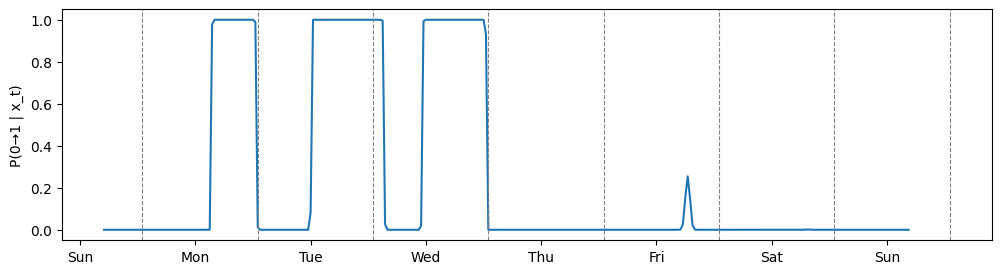

In [23]:
import matplotlib.dates as mdates
n = 48 * 7
xs = jnp.asarray(data[1])                                      # (T, D) covariates
P = jax.vmap(results.params.transition.transition_matrix)(xs)  # (T, K, K)

d = pd.to_datetime(np.asarray(dates[:n]))
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(d, P[:n, 0, 1])

ax.xaxis.set_major_locator(mdates.HourLocator(byhour=23))              # tick at each midnight
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))      # Mon, Tue, ...
for noon in pd.date_range(d[0].normalize(), d[-1], freq="D") + pd.Timedelta(hours=12):
    ax.axvline(noon, color="grey", ls="--", lw=0.8)
ax.set_ylabel("P(0→1 | x_t)")
plt.show()

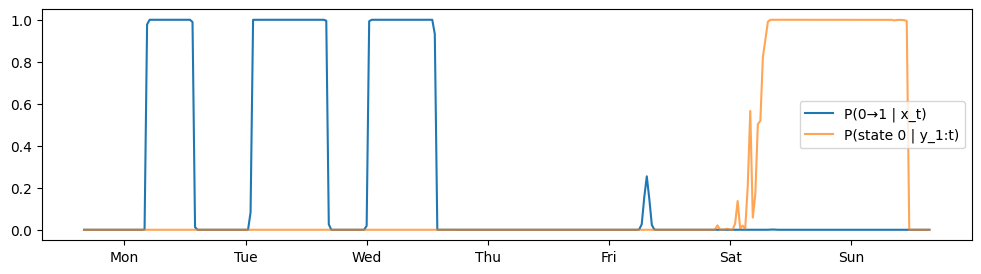

In [24]:
from src.api.v5 import ForwardAlgorithm
ys, xs, init = data
utt, f_t, u_t = ForwardAlgorithm().run(params=results.params, ys=ys, xs=xs, initial_dist=init)
fig, ax = plt.subplots(figsize=(12, 3))

M = 20
ax.plot(d, P[M: M + n, 0, 1], label="P(0→1 | x_t)")
ax.plot(d, utt[M: M + n, 0, 0], label="P(state 0 | y_1:t)", alpha=0.7)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))
ax.legend(); plt.show()

In the dynamic model the transition probability out of state 0 is a softmax of a linear predictor:

  $$
  \eta_{01}(x_t) = \alpha_{01} + \sum_c \beta_{c,01}\, x_{c,t},
  \qquad
  P(0\to 1 \mid x_t) = \frac{e^{\eta_{01}(x_t)}}{1 + \sum_{j\neq 0} e^{\eta_{0j}(x_t)}} .
  $$

  **1. The data favour a switch.** Transitions from state 0 to state 1 only happen at certain times (e.g. weekday mornings). Ideally $P(0\to1)$ would be close to 1 at those times and close to 0
  at all others.

  **2. Smooth covariates can only make a switch by blowing up.** The covariates (`off_day`, weekly and daily harmonics) vary smoothly and are bounded in $[-1, 1]$. The only way a softmax of them
  can jump from 0 to 1 is if the coefficients become very large. Then $\eta_{01}$ swings by hundreds of units and the softmax saturates. That's why we see $\hat\beta \approx 130$.

  **3. There is no finite optimum.** Every increase in $|\beta|$ makes the switch sharper. That pushes $P(0\to1)$ closer to 1 when the transition happens and closer to 0 when it doesn't. The 
  likelihood therefore keeps improving, by smaller and smaller amounts, as $|\beta| \to \infty$. This is called **separation**, the same issue as in logistic regression. The optimiser stops only 
  because the per-iteration gain falls below `tol`, which is why the gradient is not zero.

  **4. The Hessian is no longer positive definite.** When the softmax saturates, the NLL is flat in some directions (the curvature $\approx p(1-p) \approx 0$) and curves slightly downwards in one
  direction. That direction is the eigenvector of the negative eigenvalue ($\lambda_{\min} \approx -4\cdot10^{-4}$). It loads on $\alpha_{01}$ and $\beta_{\cdot,01}$, i.e. exactly the 0→1
  parameters. So the fitted point is not a local minimum.

  **5. Consequences:**
  - The Cholesky factorisation needs a positive definite matrix. It fails here and returns NaN for every standard error.
  - Even if we invert $H$ some other way, Wald standard errors and confidence intervals are not valid. They assume the likelihood is quadratic around a finite optimum, and here it isn't.
  - The parameters for transitions that essentially never happen (out of states 2 and 3) have curvature $\approx 0$. The data contain no information about them.

  **6. Fixes:**
  - Replace the harmonics for 0→1 with a covariate that matches the switch (e.g. an indicator for workday mornings).
  - Or add a ridge penalty $\tfrac{\lambda}{2}\lVert\beta\rVert^2$ so the optimum is finite.


  What happens is that the fitted model learns that in the weekends, the prob of going out of state 0 becomes very low. And due to harmocis swings, it very heavily set the weeknd covariate to a very high value, which is why we see the large $\beta$ values. This mean that the prob of going out of state 0 in the night in workdays is 1, but the chain is never in state 0 during the night in workdays, so this part of the coefficient is never used. 

In [25]:
working_hours = jnp.array([1 if 8 <= dt.hour < 17 and (dt.weekday() <= 5)  else 0 for dt in traindata.datetime ])  # 1 for working hours (8 AM to 5 PM, Mon-Fri), else 
X_raw = jnp.column_stack((X_raw, working_hours))  # Add working hours as a new covariate 

emission = results_dict["HMM(1)"].params.emission 

transition_matrix = results_dict["HMM(1)"].params.transition.transition_matrix()
beta_init = jnp.ones((len(covariate_cols) + 1, transition_matrix.shape[0], transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransition.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 

data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0 
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters


print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")

Final loss: 16364.837685405208
Converged: False


### HMM( $\beta$, 1), Shared Cols

In [26]:
from src.api.v5.hmm.transitions.dynamic_transition import DynamicTransitionColsShared 

beta_init = jnp.ones((len(covariate_cols) + 1, transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransitionColsShared.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 

results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters


print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")

results_dict["HMM(b,1) shared cols"] = results

Final loss: 16415.472838902373
Converged: True


In [27]:
H, unravel = compute_hessian(fitted_params=results.params, data=data) 

print(f"Condition number of HMM(b,1) shared cols is: {jnp.linalg.cond(H)}") 
tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H))) 
print(f"Tolerance is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}")
print(f"Number of numerical zeros: {jnp.sum(jnp.abs(jnp.linalg.eigvalsh(H)) <= tol)}")
gradient = get_gradient(params=results.params, data=data)
print(f"Gradient norm: {jnp.linalg.norm(gradient)}")

Condition number of HMM(b,1) shared cols is: 3150257192114.3594
Tolerance is: 2.7032975323377566e-11
Number of negative eigenvalues: 0
Number of numerical zeros: 0
Gradient norm: 9.253559242644282e-07


In [28]:
def lrt(ll_null, ll_alt, df):
    """Perform a likelihood ratio test given the log-likelihoods of the null and alternative models and the degrees of freedom."""
    from scipy.stats import chi2
    test_statistic = 2 * (ll_alt - ll_null)
    p_value = chi2.sf(test_statistic, df)
    return test_statistic, p_value

In [29]:
dfs = len(results_dict["HMM(b,1) shared cols"].params.transition.beta.flatten())  # number of parameters in the alternative model


test_statistic, p_value = lrt(-results_dict["HMM(1)"].loss, -results_dict["HMM(b,1) shared cols"].loss, df=dfs) 

print(f"Likelihood Ratio Test Statistic: {test_statistic:.4f}")
print(f"P-value: {p_value:.4e}")

print(f"Current number of models: {results_dict.keys()}")

Likelihood Ratio Test Statistic: 70.0005
P-value: 4.5184e-08
Current number of models: dict_keys(['HMM(1)', 'HMM(b,1)', 'HMM(b,1) shared cols'])


In [30]:
params = results_dict["HMM(b,1) shared cols"].params 
logits = params.transition.transition_logits
beta_vals = params.transition.beta 

print(f"Estimated transition logits for HMM(b,1) shared cols:\n{logits}")
print(f"Estimated beta values for HMM(b,1) shared cols:\n{beta_vals}") 


Estimated transition logits for HMM(b,1) shared cols:
[[ -7.40961841  -5.54540778  -6.41061202]
 [ -6.87435935  -5.76692895  -7.64534234]
 [-27.12461499  -4.34916095  -5.7033432 ]
 [-27.87088773 -27.85972466  -5.16263239]]
Estimated beta values for HMM(b,1) shared cols:
[[-0.16206761 -2.10467786 -2.20685288]
 [-0.99414482 -1.42765354 -0.70312992]
 [ 0.23515703  2.09843988  0.45540682]
 [ 1.693844    0.05438494  1.88799928]
 [ 2.66414268 -0.60326668  0.66737209]
 [ 2.98389927  0.60154934  2.61497959]]


Fitting with a ridge penality

In [31]:
def nll_ridge(Params: Params, data: tuple): 
    """Compute the negative log-likelihood of the HMM given the parameters and data, with ridge penalty on beta."""
    ys, xs, inital_dist, lam = data
    nll = negative_likelihood(Params, (ys, xs, inital_dist))
    beta_hat = jnp.ravel(Params.transition.beta)  # Flatten beta to a 1D array
    ridge_penalty = lam * jnp.sum(beta_hat ** 2)  # Ridge penalty term
    return nll + ridge_penalty  # Total loss = NLL + Ridge


In [32]:
emission = results_dict["HMM(1)"].params.emission 

transition_matrix = results_dict["HMM(1)"].params.transition.transition_matrix()
beta_init = jnp.ones((len(covariate_cols) + 1, transition_matrix.shape[0], transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransition.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 

data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist, 0.05)  # initial distribution: all in state 0 
results = solver.fit(params=params, loss_fn=nll_ridge, data=data)  # solve for parameters


print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")

Final loss: 16388.40823982745
Converged: True


### AR(1)-HMM(1)

In [33]:
phi = jnp.ones(STATES) * 0.1
mu = fitted_gauss_params.emission.mu(t=0, ys=0) 
std = fitted_gauss_params.emission.sigma(t=0, ys=0)

In [34]:

emission = AutoregressiveGaussEmission.from_params(mu=mu, sigma=std, phi=phi)  # emission distribution

transition = fitted_gauss_params.transition  # transition distribution 

ar1_params = Params(emission=emission, transition=transition)  # combine into Params object 

data = (traindata.ys_co2,  None, inital_dist)  # initial distribution: all in state 0

results_ar1 = solver.fit(params=ar1_params, loss_fn=negative_likelihood, data=data)  # solve for parameters

fitted_ar1_params = results_ar1.params  # fitted parameters
print(f"Final loss for AR(1)-HMM(1): {results_ar1.loss}")
print(f"Converged: {results_ar1.converged}")

results_dict["AR(1)-HMM(1)"] = results_ar1



Final loss for AR(1)-HMM(1): 13322.612529689826
Converged: True


In [35]:
H, unravel = compute_hessian(fitted_ar1_params, data)

tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H)))
print(f"Tolerance is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}") 


Tolerance is: 1.5086556393195014e-11
Number of negative eigenvalues: 0


In [36]:
phi_vals = fitted_ar1_params.emission.phi() 

print(f"Estimated phi values for AR(1)-HMM(1): {phi_vals}")

Estimated phi values for AR(1)-HMM(1): [[0.53255282 0.37294003 0.94975988 0.87092288]]


In [37]:
mu_0=fitted_ar1_params.emission.mu0
params_std_errors = compute_working_standard_errors(fitted_params=fitted_ar1_params, data=data)
std = params_std_errors.emission.mu0

lower_mu = mu_0 - 3*std 
upper_mu = mu_0 + 3*std 

mu0_range = jnp.linspace(mu_0 - 3*std, mu_0 + 3*std, 60)  # range of mu0 values to profile

nll = profile_likelihood_mu0(mu0_range, fitted_ar1_params, data, LBFGSSolver(n_iter=1000))

Text(0, 0.5, 'Likelihood')

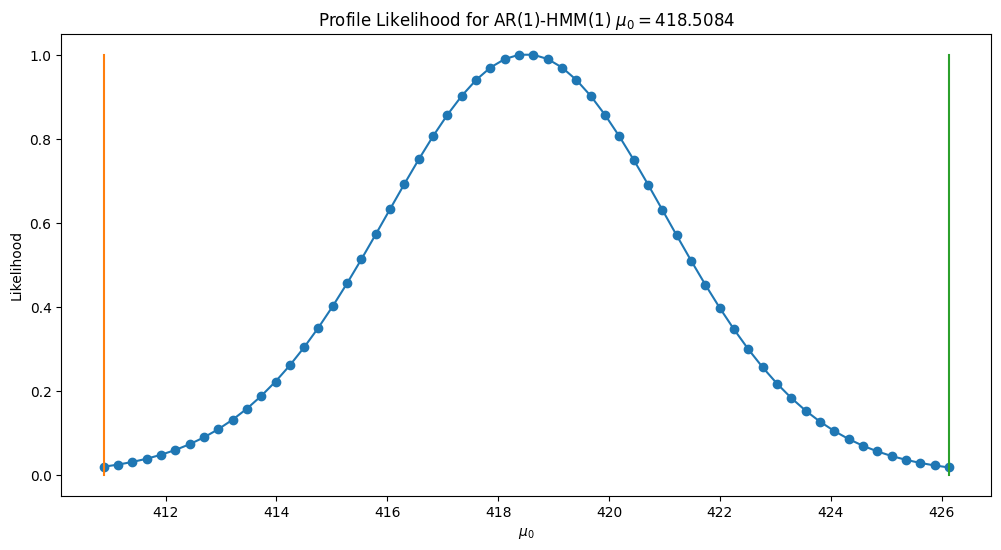

In [38]:
#Plot profile likelihood
ll = -nll  # Convert negative log-likelihood to log-likelihood for plotting
profile_likelihoods = jnp.exp(ll - jnp.max(ll))  # Convert negative log-likelihood to likelihood for plotting


plt.figure(figsize=(12, 6))
plt.plot(mu0_range, profile_likelihoods, marker='o')
plt.plot([lower_mu, lower_mu], [0, 1])
plt.plot([upper_mu, upper_mu], [0, 1])
plt.title(f"Profile Likelihood for AR(1)-HMM(1) $\mu_0=${mu_0:.4f}")
plt.xlabel("$\mu_0$")
plt.ylabel("Likelihood")

In [39]:
# Fitting different inital distributions
starts = 20

init_list = [inital_dist, jnp.array([[1.0, 0.0, 0.0, 0.0]]).T] 

inits = jax.random.uniform(jax.random.PRNGKey(0), (4, starts))

for i in range (0, starts): 
    s = inits[:, i]
    s = s / jnp.sum(s)
    init_list.append(s)

In [40]:
data_list = [(traindata.ys_co2, None, i.reshape(1,4)) for i in init_list]


ar1_params = Params(emission=emission, transition=transition)  # combine into Params object 


for i, data_set in enumerate(data_list): 
    results_run = solver.fit(params=ar1_params, loss_fn=negative_likelihood, data=data_set)  # solve for parameters
    print(f"Run {i}, converged={results_run.converged}, loss = {results_run.loss}, $\mu_0$={results_run.params.emission.mu0}")
    

Run 0, converged=True, loss = 13322.612529689826, $\mu_0$=418.50839917416795
Run 1, converged=True, loss = 13326.126895742844, $\mu_0$=418.6486041347085
Run 2, converged=True, loss = 13322.833999493758, $\mu_0$=418.5074881030982
Run 3, converged=True, loss = 13322.500298142857, $\mu_0$=418.5081125072381
Run 4, converged=True, loss = 13322.732204920794, $\mu_0$=418.5087137283814
Run 5, converged=True, loss = 13323.42923787257, $\mu_0$=418.50509170895305
Run 6, converged=True, loss = 13322.378033079352, $\mu_0$=418.5101109911385
Run 7, converged=True, loss = 13322.82190752826, $\mu_0$=418.5076759779534
Run 8, converged=True, loss = 13322.776206040115, $\mu_0$=418.5079072688053
Run 9, converged=True, loss = 13322.61227177602, $\mu_0$=418.51010024176804
Run 10, converged=True, loss = 13322.34313206129, $\mu_0$=418.509427064782
Run 11, converged=True, loss = 13323.049441635238, $\mu_0$=418.50566834714795
Run 12, converged=True, loss = 13323.644681705173, $\mu_0$=418.5084762842553
Run 13, co

### AR(1)-HMM($\beta$, 1), Shared columns

In [41]:
for modelname, result in results_dict.items(): 
    print(f"Model: {modelname}, Loss: {result.loss}, Converged: {result.converged}, Estimated mu0: {result.params.emission.mu0}")

Model: HMM(1), Loss: 16450.4731085659, Converged: True, Estimated mu0: 419.6461589290379
Model: HMM(b,1), Loss: 16369.116842974487, Converged: False, Estimated mu0: 421.81395533932795
Model: HMM(b,1) shared cols, Loss: 16415.472838902373, Converged: True, Estimated mu0: 420.3416061797412
Model: AR(1)-HMM(1), Loss: 13322.612529689826, Converged: True, Estimated mu0: 418.50839917416795


In [42]:
emission = results_dict["AR(1)-HMM(1)"].params.emission
transition = results_dict["HMM(b,1) shared cols"].params.transition
params = Params(emission=emission, transition=transition)  # combine into Params object

data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0

solver = LBFGSSolver(n_iter=100_000)  # number of iterations for the optimizer

results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters

print(f"Final loss for AR(1)-HMM(b,1) shared cols: {results.loss}")
print(f"Converged: {results.converged}")

results_dict["AR(1)-HMM(b,1) shared cols"] = results

Final loss for AR(1)-HMM(b,1) shared cols: 13268.77436514352
Converged: True


In [43]:
H, unravel = compute_hessian(fitted_params=results.params, data=data)

tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H)))
print(f"Tolerance is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}")    
eigvals = jnp.linalg.eigvalsh(H)
print(f"Eigenvalues of Hessian: {eigvals}") 

Tolerance is: 3.119485613577642e-11
Number of negative eigenvalues: 0
Eigenvalues of Hessian: [9.98865570e-08 1.08357175e-07 1.08675105e-07 1.10018188e-07
 1.18464834e-07 1.15680125e-03 2.23125036e-03 2.37174323e-02
 7.22224486e-02 1.30386294e-01 1.39836844e-01 2.27569633e-01
 2.55579881e-01 3.97935013e-01 8.51996722e-01 1.23234298e+00
 1.39308502e+00 1.66632305e+00 1.90528190e+00 2.03865588e+00
 2.25433129e+00 2.47037962e+00 2.59522426e+00 3.51966107e+00
 7.17831022e+00 1.29826547e+01 1.33776009e+01 1.45355326e+01
 1.69231134e+01 2.26348499e+01 2.60219234e+01 2.90996121e+01
 4.30296770e+01 6.35654270e+01 1.04295734e+02 3.30832389e+02
 3.90288692e+02 4.75501788e+02 8.86740055e+02 1.28545789e+03
 1.55840320e+03 3.34497958e+03]


In [44]:
phi_vals = results.params.emission.phi()
print(f"Estimated phi values for AR(1)-HMM(b,1) shared cols: {phi_vals}")

Estimated phi values for AR(1)-HMM(b,1) shared cols: [[0.57759907 0.17672009 0.95067532 0.86847271]]


### AR(2 to 8)-HMM(1)

In [45]:
init_phis = jnp.ones((2, STATES)) * 0.1
init_mu = fitted_gauss_params.emission.mu(t=0, ys=0)
init_std = fitted_gauss_params.emission.sigma(t=0, ys=0) 

In [46]:
def fit_ar1(emission: AutoregressiveGaussEmission): 
    """Fit an AR(1)-HMM model with the given emission distribution."""
    transition = results_dict["HMM(1)"].params.transition
    params = Params(emission=emission, transition=transition)  # combine into Params object
    data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0
    solver = LBFGSSolver(n_iter=100_000)  # number of iterations for the optimizer
    results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters
    minimum = is_minimum(params=results.params, data=data)  # check if the fitted parameters correspond to a local minimum
    return results, minimum

def is_minimum(params: Params, data: tuple) -> bool:
    """Check if the fitted parameters correspond to a local minimum by examining the Hessian."""
    H, _ = compute_hessian(fitted_params=params, data=data)
    eigvals = jnp.linalg.eigvalsh(H)
    tol = H.shape[0] * jnp.finfo(H.dtype).eps * jnp.max(jnp.abs(eigvals))
    num_negative = jnp.sum(eigvals < -tol)
    return bool(num_negative == 0)  # True if no negative eigenvalues, indicating a local

def init_phi_values(num_phis: int, num_states: int) -> jnp.ndarray:
    """Initialize phi values for the AR(1) emission distribution."""
    return jnp.ones((num_phis, num_states)) * 0.1  # Example initialization 

init_phi_list = [init_phi_values(num_phis, STATES) for num_phis in range(2, 9)]  # Initialize for 1 to 3 phis
emission_list = [AutoregressiveGaussEmission.from_params(mu=init_mu, sigma=init_std, phi=phi) for phi in init_phi_list]

In [47]:
results_list = [ ]

for emission in emission_list:
    results, min = fit_ar1(emission)
    if (min): 
        results_list.append(results)
    print(f"Fitted AR(1)-HMM with {emission.phi().shape[0]} phis: Loss={results.loss}, Converged={results.converged}, is minum = {min}, Estimated mu0={results.params.emission.mu0}") 


Fitted AR(1)-HMM with 2 phis: Loss=13119.001329451425, Converged=True, is minum = False, Estimated mu0=454.26251103199843
Fitted AR(1)-HMM with 3 phis: Loss=13063.212314772047, Converged=True, is minum = False, Estimated mu0=416.2081442631089
Fitted AR(1)-HMM with 4 phis: Loss=13014.531825411714, Converged=True, is minum = True, Estimated mu0=449.19378176131187
Fitted AR(1)-HMM with 5 phis: Loss=12999.257819822784, Converged=True, is minum = True, Estimated mu0=446.71314193977514
Fitted AR(1)-HMM with 6 phis: Loss=12984.66409143437, Converged=True, is minum = True, Estimated mu0=447.1798049639092
Fitted AR(1)-HMM with 7 phis: Loss=12970.744515942772, Converged=True, is minum = False, Estimated mu0=445.7453850857624
Fitted AR(1)-HMM with 8 phis: Loss=12962.189807309871, Converged=True, is minum = False, Estimated mu0=445.9156884442221


In [48]:
results_dict["AR(2-8)-HMM(1)"] = results_list 

## Fitting Multivariate Model

We now fit multivariate models to the CO2 and Humidity data. The emission model is a multivariate Gaussian with a diagonal covariance matrix. The transition model is a dynamic transition model with covariates.

### Multi-HMM(1)

In [49]:
data = (traindata.ys, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0 

mu_init = jnp.quantile(traindata.ys, jnp.linspace(0.05, 0.95, STATES), axis=0).T  # initial guess for means
std_init = jnp.std(traindata.ys, axis=0)[:, None] * jnp.ones((STATES, ))[None, :]  # initial guess for stds 
emission = MultivariateGaussEmission.from_params(mu=mu_init, sigma=std_init)  # emission distribution
transition_matrix = jnp.diag(jnp.ones(STATES)) * 0.7 + jnp.ones((STATES, STATES)) * 0.3 / STATES  # initial guess for transition matrix
transition = StaticTransition.from_params(transition_matrix=transition_matrix)  # transition distribution
params = Params(emission=emission, transition=transition)  # combine into Params object


In [50]:
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters

In [51]:
print(f"Final loss for Multivariate HMM(1): {results.loss}")
print(f"Converged: {results.converged}")

Final loss for Multivariate HMM(1): 19838.39373150883
Converged: True


In [52]:
#Lets check if its a minimum
H, unravel = compute_hessian(fitted_params=results.params, data=data)
tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H)))
print(f"Tolerance is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(H)) <= tol)
print(f"Number of numerical zeros: {zero_eigenvalues}")

Tolerance is: 1.3570059611847229e-10
Number of negative eigenvalues: 0
Number of numerical zeros: 3


In [53]:
Hs, d = scale_hessian(H) 
tol = Hs.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(Hs)))
print(f"Tolerance for scaled Hessian is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(Hs) < -tol)
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(Hs)) <= tol)
print(f"Number of numerical zeros for scaled Hessian: {zero_eigenvalues}")

Tolerance for scaled Hessian is: 1.8560618555264257e-14
Number of negative eigenvalues for scaled Hessian: 0
Number of numerical zeros for scaled Hessian: 0


In [56]:
results_dict["Multi-HMM(1)"] = results

In [54]:
# We have found a minimum 
mu_0 = results.params.emission.mu0[0]
params_std_errors = compute_working_standard_errors(fitted_params=results.params, data=data)
std = params_std_errors.emission.mu0[0]
print(f"Estimated mu0: {mu_0}, SE: {std} of Co2 in Multivariate HMM(1)")

Estimated mu0: 465.53463818581116, SE: 1.6283820894016297 of Co2 in Multivariate HMM(1)


### Multi-HMM($\beta$, 1), Shared Cols

In [121]:
emission = results_dict["Multi-HMM(1)"].params.emission 
transition = results_dict["HMM(b,1) shared cols"].params.transition
params = Params(emission=emission, transition=transition)  # combine into Params object
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters

print(f"Final loss for Multivariate HMM(b,1) shared cols: {results.loss}")
print(f"Converged: {results.converged}")

Final loss for Multivariate HMM(b,1) shared cols: 19807.36148974221
Converged: True


In [122]:
#Lets check its a minimum
H, unravel = compute_hessian(fitted_params=results.params, data=data)
tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H)))
print(f"Tolerance for Hessian is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(H)) <= tol)
print(f"Number of numerical zeros for Hessian: {zero_eigenvalues}")

Tolerance for Hessian is: 2.235033102894067e-10
Number of negative eigenvalues for scaled Hessian: 0
Number of numerical zeros for Hessian: 2


In [123]:
print("Is there any logits going to inf?")
print(results.params.transition.beta )
print(results.params.transition.transition_logits)

Is there any logits going to inf?
[[ 1.41354787 -0.64137005 -2.07581271]
 [ 0.82633107  0.20333274 -0.60587035]
 [-1.27002761  0.88625519  0.37333529]
 [ 0.44376406 -0.13450888  1.84432972]
 [-0.80719741 -0.32547599  0.50916626]
 [ 0.06946756  0.31721059  2.45816046]]
[[-5.01196839e+00 -1.27670993e+04 -7.16520656e+00]
 [-6.20697855e+00 -5.20248682e+00 -6.38585642e+00]
 [-7.83127383e+00 -4.60455887e+00 -5.83456229e+00]
 [-7.40969608e+00 -2.78670093e+01 -5.23121359e+00]]


In [124]:
eigenvals = jnp.linalg.eigvalsh(H)
mask = jnp.abs(eigenvals) <= tol 
print(f"Zero eigenvalues: {eigenvals[mask]}")

Zero eigenvalues: [-2.36093953e-12  3.39178521e-14]


In [125]:
jnp.diagonal(H)

Array([4.80641044e+00, 0.00000000e+00, 9.86636068e-01, 3.94960395e+00,
       4.69968504e+00, 3.54923200e+00, 9.93811032e-01, 7.08813661e+00,
       8.80471323e+00, 9.83769891e-01, 8.23089759e-10, 1.30239688e+01,
       3.89918650e+00, 4.40148065e+00, 1.97859729e+00, 5.09508485e+00,
       5.96663868e+00, 1.24823942e+01, 5.64531939e+00, 5.77634408e+00,
       1.43364574e+01, 5.11915179e+00, 5.32602534e+00, 1.18670242e+01,
       5.45395726e+00, 5.65230313e+00, 1.45237043e+01, 5.81882297e+00,
       4.61295591e+00, 1.91983215e+01, 1.62746556e-13, 1.72246041e+03,
       1.54142978e+03, 1.33336490e+04, 4.05704304e+03, 3.88354642e+00,
       4.61969070e-01, 7.59819857e+03, 5.56296376e+02, 1.34002709e+03,
       1.20042431e+03, 1.41688062e+03, 5.79408311e+02, 1.35853658e+03,
       1.54099313e+03, 1.34160303e+03], dtype=float64)

In [126]:
d = 1.0 / jnp.sqrt(jnp.abs(jnp.diag(H)))
print(f"Diagonal scaling factors: {d}")
Hs = d[:, None] * H * d[None, :]       # unit-magnitude diagonal
print("--------------") 
print(Hs)

tol = Hs.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(Hs)))
print(f"Tolerance for Hessian is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(Hs) < -tol)
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(Hs)) <= tol)
print(f"Number of numerical zeros for Hessian: {zero_eigenvalues}")

Diagonal scaling factors: [4.56130983e-01            inf 1.00674969e+00 5.03179832e-01
 4.61281060e-01 5.30802312e-01 1.00310892e+00 3.75607245e-01
 3.37009693e-01 1.00821519e+00 3.48559080e+04 2.77094768e-01
 5.06422504e-01 4.76651102e-01 7.10920922e-01 4.43020976e-01
 4.09388021e-01 2.83042110e-01 4.20877531e-01 4.16076773e-01
 2.64106491e-01 4.41978350e-01 4.33309675e-01 2.90288002e-01
 4.28197508e-01 4.20617442e-01 2.62398472e-01 4.14555258e-01
 4.65597187e-01 2.28227709e-01 2.47881489e+06 2.40949138e-02
 2.54705385e-02 8.66015151e-03 1.56998388e-02 5.07441228e-01
 1.47127397e+00 1.14721464e-02 4.23981478e-02 2.73176421e-02
 2.88624112e-02 2.65664406e-02 4.15439359e-02 2.71309082e-02
 2.54741469e-02 2.73015928e-02]
--------------
[[ 1.00000000e+00             nan -1.05750845e-02 ... -9.70938129e-03
  -9.82708696e-04 -2.02679495e-03]
 [            nan             nan             nan ...             nan
              nan             nan]
 [-1.05750845e-02             nan  1.00000000e

In [127]:
labels = hessian_labels(results.params)
theta, _ = ravel_pytree(eqx.partition(results.params, eqx.is_array)[0])
diag = jnp.diag(H)
for i in jnp.argsort(diag)[:5]:
    print(f"{labels[i]:40s} H_ii={diag[i]:.2e}  value={theta[i]:.3f}")

transition.transition_logits[0->2]       H_ii=0.00e+00  value=-12767.099
emission.log_mu_diff[0,0]                H_ii=1.63e-13  value=-29.475
transition.transition_logits[3->1]       H_ii=8.23e-10  value=-27.867
emission.mu0[0]                          H_ii=4.62e-01  value=465.482
transition.transition_logits[3->0]       H_ii=9.84e-01  value=-7.410


We now fit with freezing parameters for the tranisiotin and emission model based on the previoues results. 

In [147]:
freeze = [("transition_logits", (0, 1))]

results = solver.fit(params=params, loss_fn=negative_likelihood, data=data, frozen=freeze)  # solve for parameters

print(f"Final loss for Multivariate HMM(b,1) shared cols: {results.loss}")
print(f"Converged: {results.converged}")
results_dict["Multi-HMM(b,1) shared cols frozen"] = results

Final loss for Multivariate HMM(b,1) shared cols: 19808.630585821964
Converged: True


In [144]:
import numpy as np
from jax.flatten_util import ravel_pytree
from src.api.v5.solvers.freezer import Freezer
def compute_trainable_hessian(params, loss_fn, data, frozen=None):
    """Hessian of loss_fn w.r.t. the trainable entries only (leaf- and element-frozen ones removed)."""
    freezer = Freezer(frozen)
    trainable, static = eqx.partition(params, freezer.filter_spec(params))   # drops whole-leaf freezes
    theta, unravel = ravel_pytree(trainable)
    def leaf_mask(path, leaf):                                                 # 0 at element freezes
        m = jnp.ones(leaf.shape)
        for idx in freezer.elements.get(freezer._leaf_name(path), []):
            m = m.at[idx].set(0.0)
        return m
    mask, _ = ravel_pytree(jax.tree_util.tree_map_with_path(leaf_mask, trainable))
    free_idx = np.flatnonzero(np.asarray(mask))
    def loss_free(theta_free):
        full = theta.at[free_idx].set(theta_free)                              # frozen entries stay at their values
        return loss_fn(eqx.combine(unravel(full), static), data)
    H = jax.hessian(loss_free)(theta[free_idx])
    return H, theta[free_idx], free_idx, trainable
def trainable_labels(trainable, free_idx):
    """One label per row/column of the trainable Hessian."""
    labels = []
    for path, leaf in jax.tree_util.tree_flatten_with_path(trainable)[0]:
        name = jax.tree_util.keystr(path).lstrip(".")
        labels += [f"{name}[{','.join(map(str, i))}]" for i in np.ndindex(leaf.shape)] or [name]
    return [labels[i] for i in free_idx]
#Usage, including standard errors:
freeze = [("transition_logits", (0, 1))]
H, theta_free, free_idx, trainable = compute_trainable_hessian(results.params, negative_likelihood, data, freeze)
labels = trainable_labels(trainable, free_idx)
d = 1.0 / jnp.sqrt(jnp.abs(jnp.diag(H)))
Hs = d[:, None] * H * d[None, :]
cov = cho_solve(cho_factor(Hs), jnp.eye(len(d))) * jnp.outer(d, d)
se = jnp.sqrt(jnp.diag(cov))
pd.DataFrame({"value": theta_free, "se": se}, index=labels)

,value,se
"transition.transition_logits[0,0]",-5.006875,8.020100e-01
"transition.transition_logits[0,2]",-7.161440,1.160300e+00
"transition.transition_logits[1,0]",-6.204964,8.530121e-01
"transition.transition_logits[1,1]",-4.897828,7.108255e-01
"transition.transition_logits[1,2]",-6.393718,8.118252e-01
"transition.transition_logits[2,0]",-7.829766,1.182385e+00
"transition.transition_logits[2,1]",-4.383240,5.605896e-01
"transition.transition_logits[2,2]",-5.833208,6.806658e-01
"transition.transition_logits[3,0]",-7.409287,1.153794e+00
"transition.transition_logits[3,1]",-27.870173,3.941373e+04


In [146]:
eigvals = jnp.linalg.eigvalsh(Hs)
tol = Hs.shape[0] * eps * jnp.max(jnp.abs(eigvals))
print(f"Tolerance for scaled Hessian is: {tol}")
negative_eigenvalues = jnp.sum(eigvals < -tol)  
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(eigvals) <= tol)
print(f"Number of numerical zeros for scaled Hessian: {zero_eigenvalues}")

Tolerance for scaled Hessian is: 3.099927926514832e-14
Number of negative eigenvalues for scaled Hessian: 0
Number of numerical zeros for scaled Hessian: 0


In [173]:
_, f_t, _ = ForwardAlgorithm().run(params=results.params, ys=data[0], xs=data[1], initial_dist=data[2])
print("clipped steps:", int(jnp.sum(f_t <= 1e-10)), "of", len(f_t))

clipped steps: 2751 of 2752


### AR(1)-Multi-HMM(1)

In [159]:
results_dict.keys()

dict_keys(['HMM(1)', 'HMM(b,1)', 'HMM(b,1) shared cols', 'AR(1)-HMM(1)', 'AR(1)-HMM(b,1) shared cols', 'AR(2-8)-HMM(1)', 'Multi-HMM(1)', 'Multi-HMM(b,1) shared cols frozen'])

In [162]:
phi_init = jnp.ones((1, 2, STATES)) * 0.05 
mu_vals = results_dict["Multi-HMM(1)"].params.emission.mu(t=0, ys=0)
std_vals = results_dict["Multi-HMM(1)"].params.emission.sigma(t=0, ys=0)  

emission = MultivariateAutoregressiveGaussEmission.from_params(mu=mu_vals, sigma=std_vals, phi=phi_init)  # emission distribution
transition = results_dict["HMM(1)"].params.transition
params = Params(emission=emission, transition=transition)  # combine into Params object
data = (traindata.ys, None, inital_dist)  # initial distribution: all in state 0
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  #solve for parameters

print(f"Final loss for Multivariate AR(1)-HMM(b,1) shared cols frozen: {results.loss}")
print(f"Converged: {results.converged}")

Final loss for Multivariate AR(1)-HMM(b,1) shared cols frozen: 63344.115908266234
Converged: True


In [166]:
labels = hessian_labels(results.params)
theta, _ = ravel_pytree(eqx.partition(results.params, eqx.is_array)[0])
diag = jnp.diag(H)
for i in jnp.argsort(diag, descending=False)[:10]:
    print(f"{labels[i]:40s} H_ii={diag[i]:.2e}  value={theta[i]:.3f}")

transition.transition_logits[1->0]       H_ii=-9.96e-17  value=7.977
transition.transition_logits[3->1]       H_ii=-3.98e-17  value=-27.860
transition.transition_logits[0->3]       H_ii=-2.81e-31  value=288.895
transition.transition_logits[3->0]       H_ii=-3.57e-56  value=-26.410
transition.transition_logits[1->2]       H_ii=-3.01e-165  value=40.788
transition.transition_logits[2->0]       H_ii=0.00e+00  value=-13.372
transition.transition_logits[2->3]       H_ii=0.00e+00  value=166.105
transition.transition_logits[3->2]       H_ii=0.00e+00  value=16.997
emission.log_mu_diff[0,0]                H_ii=0.00e+00  value=-29.400
emission.log_mu_diff[0,1]                H_ii=0.00e+00  value=7.145


In [ ]:
freeze = [("transition_logits", (0, 1))]